# Classifying existence of Galaxy using Quantum Machine Learning


In the following code notebook, you'll learn how to develop a galaxy detection technique from the telescope image via Quantum Machine Learning.

-----

The accuracy of the model is $86\%$ via a quantum machine learning model from NASA image. The image is further divided into a small $16 \times 16$ image as input data. 

-----

Then the data is encoded and trained using a quantum circuit using the parameterized quantum circuit taken from the paper [Expressibilitty and entangling capability of parameterized quantum circuit for hybrid quantum-classical algorithms](https://arxiv.org/abs/1905.10876).

-----

With the high expressibility of the circuit, the model is trained and tested with Cross-Entropy as the Loss function and **L-BFGS** algorithm for optimization.


This algorithm is realized in **PyTorch** and **Qiskit** machine learning module.

## Pre-Processing of Image


Import necessary Libraries for Image pre-processing

In [1]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import os

## Pre-Processing Step

The below step takes the original image taken by the telescope which is around $3$ MB each. It reshapes the images in the $2463 \times 2895$ dimensions and normalized, and divided into equal $16 \times 16$ pieces. The results are named by the nymber it represents and saved in the `result` folder in grayscale.

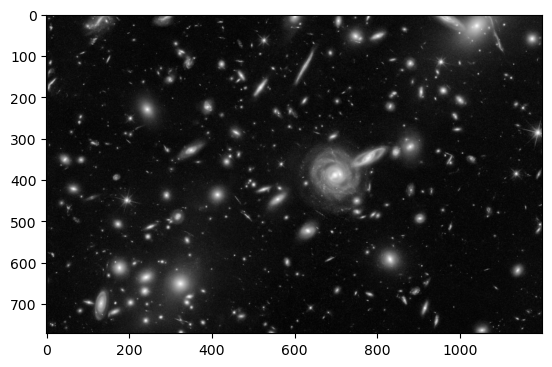

Image dimensions: 1200x771
Image partitioning complete.


In [4]:
# Load the original image in grayscale
img = Image.open('original_image.jpg').convert('L')
plt.imshow(img, cmap='gray')
plt.show()

# Get the actual dimensions of the image
width, height = img.size
print(f"Image dimensions: {width}x{height}")

# Convert image to a numpy array
img = np.asarray(img)

# Define the cut size
cut = 128

# Loop through the image and save each partitioned image
for i in range(height // cut):
    for j in range(width // cut):
        cutimg = img[i * cut:(i + 1) * cut, j * cut:(j + 1) * cut]
        plt.imsave(f'result/{i}_{j}.jpg', cutimg, cmap='gray')

print("Image partitioning complete.")

## Visualize one of the Images

Here we'll visualize , one of the images from the result folder , which we will use to further train and test our data.

In [6]:
# Load the original image and convert it to grayscale
img = Image.open('original_image.jpg').convert('L')
img_array = np.asarray(img)

resize_size = (16, 16)
# Directory to save the partitioned images
result_dir = 'result'
os.makedirs(result_dir, exist_ok=True)

# Partition the image and save each partition as a separate .jpg file
for i in range(img_array.shape[0] // cut):
    for j in range(img_array.shape[1] // cut):
        # Extract the 128x128 partition
        partition = img_array[i*cut:(i+1)*cut, j*cut:(j+1)*cut]
        
        # Convert to an image and save as a .jpg file
        partition_img = Image.fromarray(partition)
        partition_img.save(f'{result_dir}/{i}_{j}.jpg')

# Verify and process each saved partition
for i in range(img_array.shape[0] // cut):
    for j in range(img_array.shape[1] // cut):
        try:
            # Open, resize to 16x16, and convert to grayscale array
            img16 = Image.open(f'{result_dir}/{i}_{j}.jpg').resize(resize_size).convert('L')
            img16_array = np.asarray(img16)

            # Display or further process img16_array as needed
            print(f'Processed tile ({i},{j}) - Array shape: {img16_array.shape}')

        except FileNotFoundError:
            print(f"File {result_dir}/{i}_{j}.jpg not found.")

Processed tile (0,0) - Array shape: (16, 16)
Processed tile (0,1) - Array shape: (16, 16)
Processed tile (0,2) - Array shape: (16, 16)
Processed tile (0,3) - Array shape: (16, 16)
Processed tile (0,4) - Array shape: (16, 16)
Processed tile (0,5) - Array shape: (16, 16)
Processed tile (0,6) - Array shape: (16, 16)
Processed tile (0,7) - Array shape: (16, 16)
Processed tile (0,8) - Array shape: (16, 16)
Processed tile (1,0) - Array shape: (16, 16)
Processed tile (1,1) - Array shape: (16, 16)
Processed tile (1,2) - Array shape: (16, 16)
Processed tile (1,3) - Array shape: (16, 16)
Processed tile (1,4) - Array shape: (16, 16)
Processed tile (1,5) - Array shape: (16, 16)
Processed tile (1,6) - Array shape: (16, 16)
Processed tile (1,7) - Array shape: (16, 16)
Processed tile (1,8) - Array shape: (16, 16)
Processed tile (2,0) - Array shape: (16, 16)
Processed tile (2,1) - Array shape: (16, 16)
Processed tile (2,2) - Array shape: (16, 16)
Processed tile (2,3) - Array shape: (16, 16)
Processed 

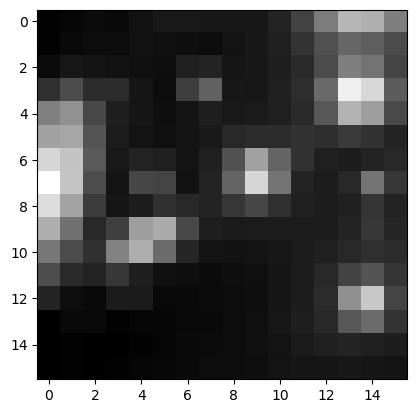

Processed image array shape: (16, 16)


In [8]:
# Open the specific image with .jpg extension, resize, and convert to grayscale
img16 = Image.open('result/{}_{}.jpg'.format(5, 1)).resize((16, 16)).convert('L')
plt.imshow(img16, cmap='gray')
plt.show()

# Convert to a numpy array for further processing
img16_array = np.asarray(img16, dtype=np.float64).reshape((16, 16))
print("Processed image array shape:", img16_array.shape)